# Example calculation of bond autocorrelation function (Csw)

In [ ]:
from vast_pea.lammps_bonds import bond_dynamics
from vast_pea.computers import compute_bond_autocorrelation

import matplotlib.pyplot as plt
from matplotlib import colormaps
colormap = 'plasma'
cmap = colormaps.get_cmap(colormap).resampled(10) # colormap for plotting multiple temperatures. Using a higher number than the number of temperatures (8) skips the really light yellow colors

## Calculate the bond autocorrelation function (Csw)

In [2]:
# start by reading/restoring a bond_dynamics object
bd = bond_dynamics(path="../../data/BER/save/",
                   pattern="afd_600K.bond_data.bonds.nc",
                   restore=True
                   )

bond_list = bd.get_bonds_setlist() # get list of sets of bonds. Each element of this list is the set of bonds for a specific timestep
csw = compute_bond_autocorrelation(bond_list) # get csw
csw

	File list contains 1 files
	Bond Dynamics done!


[1.0,
 1.0,
 1.0,
 0.3351063829787234,
 0.1702127659574468,
 0.10106382978723404,
 0.02127659574468085,
 0.010638297872340425,
 0.0026595744680851063,
 0.0]

## Plot the Csw

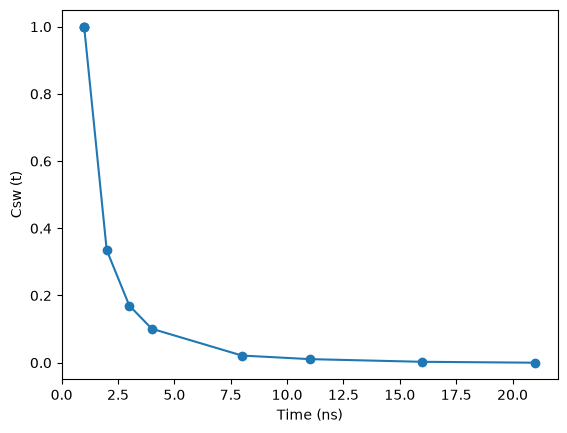

In [3]:
plt.plot(bd.timesteps/1e6, csw, 'o-')
plt.xlabel("Time (ns)")
plt.ylabel("Csw (t)")
plt.show()

## Plot all temperatures in log xscale

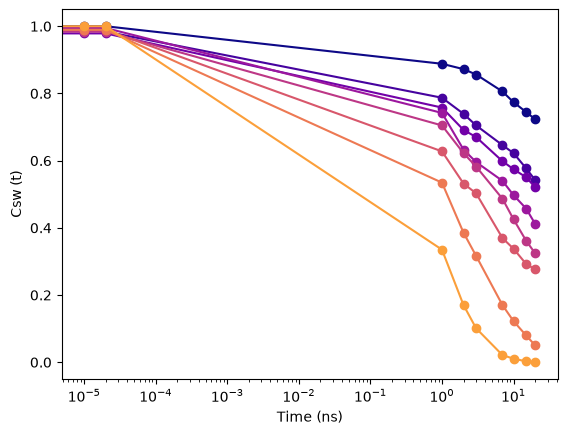

In [4]:
temperatures = [
    '325K',
    '350K',
    '375K',
    '400K',
    '425K',
    '450K',
    '500K',
    '600K'
]

for i, t in enumerate(temperatures):
    bd = bond_dynamics(path="../../data/BER/save/",
                    pattern="afd_{}.bond_data.bonds.nc".format(t),
                    restore=True,
                    verbose=False
                    )

    time = bd.timesteps / 1e6 - 1 # -1 since the BER part starts at 1ns after equilibration
    csw = compute_bond_autocorrelation(bd.get_bonds_setlist())

    plt.plot(time, csw, 'o-', c=cmap(i), label=t)

plt.xscale('log')
plt.xlabel("Time (ns)")
plt.ylabel("Csw (t)")
plt.show()